<a href="https://colab.research.google.com/github/Tharul-Fernando/CM2604-Telco-Customer-Churn/blob/main/01_EDA_Telco_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

# Mount the drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent chart style
sns.set_theme(style = "whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
file_path = ("/content/drive/MyDrive/ML_Coursework/data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(file_path)

# Display the first 5 customer records
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Display the number of rows and columns
print("Rows and columns:",df.shape)
print("Number of customers:", df.shape[0])
print("Number of columns:", df.shape[1])

Rows and columns: (7043, 21)
Number of customers: 7043
Number of columns: 21


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# Summary of numerical variables
display(df.describe())

# Summary of categorical variables
display(df.describe(include="object"))


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [7]:
# Count missing values in every column
print("Missing values:")
print(df.isnull().sum())

# Check blank or whitespace-only TotalCharges values
blank_total = df["TotalCharges"].astype(str).str.strip().eq("")

print("\nBlank TotalCharges:", blank_total.sum())


Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank TotalCharges: 11


In [8]:
# Check for blank strings in all text columns
text_columns = df.select_dtypes(include=["object", "string"]).columns

blank_counts = df[text_columns].apply(
    lambda col: col.astype("string").str.strip().eq("").sum()
)

print("\nBlank values in each text column:")
print(blank_counts)



Blank values in each text column:
customerID           0
gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
Churn                0
dtype: int64


In [9]:
# Inspect rows with black TotalCharges
blank_rows = df[
    df["TotalCharges"].astype(str).str.strip() == ""
]

display(
    blank_rows[
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [10]:
print("Duplicated rows:",df.duplicated().sum())

print("Duplicate customer IDs:",df.duplicated("customerID").sum())

Duplicated rows: 0
Duplicate customer IDs: 0


### Observation 1: Dataset Overview and Data Quality

**Observation:** The dataset contains 7,043 customer records and 21 attributes, including the target variable `Churn`. No duplicate records or customer IDs were identified. Although the initial missing-value check returned zero null values, further inspection revealed 11 blank entries in `TotalCharges`. All 11 customers had a tenure of zero months.

**Interpretation:** The blank values may be associated with newly registered customers who have not yet accumulated charges. Additionally, `TotalCharges` was identified as an object rather than a numerical attribute.

**Implication:** The `TotalCharges` attribute requires conversion to a numerical data type and appropriate handling of its blank values before model training. The original dataset should be preserved while these preprocessing decisions are implemented.

In [11]:
# Number of Churned and non-Chured customers
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True)*100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


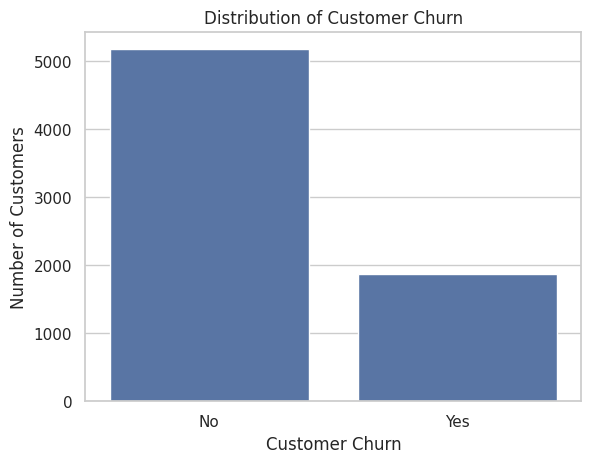

In [12]:
sns.countplot(
    data = df,
    x = "Churn",
    order = ["No", "Yes"]
)

plt.title("Distribution of Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

### Observation 2: Customer Churn Distribution

**Observation:** Out of 7,043 customers, 5,174 (73.46%) did not churn, while 1,869 (26.54%) churned. This indicates an imbalance between the two target classes, with significantly more non-churning customers.

**Interpretation:** The class imbalance could cause machine learning models to favour the majority class (non-churning customers), potentially resulting in poor identification of customers who are likely to leave.

**Implication:** Model performance should be evaluated using metrics such as precision, recall and F1-score rather than relying solely on accuracy. These metrics will help assess how effectively the models identify customers who churn.

,Churn
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


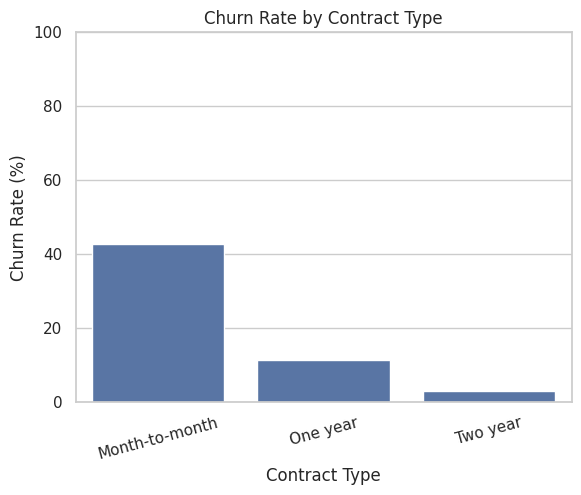

In [13]:
# Calculate the churn rate for each contract type
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

display(contract_churn)

print()

# Plot churn rates
sns.barplot(
    x = contract_churn.index,
    y = contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation = 15)

plt.show()

### Observation 3: Churn Rate by Contract Type

**Observation:** Month-to-month customers have the highest churn rate at 42.71%, followed by one-year contracts at 11.27% and two-year contracts at 2.83%.

**Interpretation:** Customers with shorter contracts appear more likely to churn, while those with longer contracts tend to remain with the company. This may be related to differences in customer commitment or flexibility.

**Implication:** Contract type could be an important feature for predicting customer churn. Therefore, it should be included as a potential predictor when developing the machine learning models.

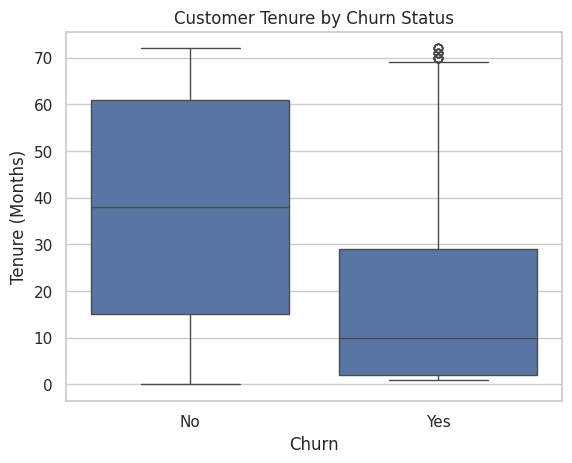


Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [14]:
sns.boxplot(
    data = df,
    x = "Churn",
    y = "tenure",
    order = ["No", "Yes"]
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

print()
# Calculate median tenure by churn status
print(df.groupby("Churn")["tenure"].median())

### Observation 4: Customer Tenure and Churn

**Observation:** The box plot shows that customers who churned generally had shorter tenure compared to those who remained with the company. The median tenure is 10 months for churned customers and 38 months for non-churned customers.

**Interpretation:** Customers who have been with the company for a shorter period appear more likely to churn, while long-term customers tend to remain subscribed. This suggests a relationship between customer tenure and churn behaviour.

**Implication:** Tenure could be an important numerical feature for predicting customer churn and should be considered during model development.

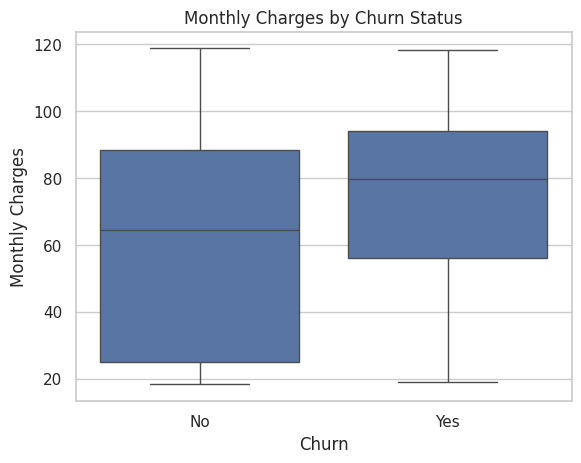

,mean,median,std
Churn,,,
No,61.265124,64.425,31.092648
Yes,74.441332,79.650,24.666053


In [15]:
# Compare monthly chargers for both churn classes
sns.boxplot(
    data = df,
    x = "Churn",
    y = "MonthlyCharges",
    order = ["No", "Yes"]
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

print()

# Summary statistics for each group
display(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean","median","std"])
)

### Observation 5: Monthly Charges and Customer Churn

**Observation:** The box plot indicates that customers who churned generally had higher monthly charges than those who remained. The average monthly charge was approximately \$74.44 for churned customers, compared to \$61.27 for non-churned customers.

**Interpretation:** Higher monthly charges appear to be associated with customer churn. However, other factors, such as contract type and subscribed services, may also influence this relationship.

**Implication:** Monthly charges could be a useful numerical feature for predicting churn and should be considered during model development.